# EJERCICIOS

In [2]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_diabetes, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    cross_val_predict,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR


In [3]:
warnings.filterwarnings("ignore", category=FutureWarning)

## EJERCICIO 1

Imagina que estás usando regresión polinomial. Trazas las curvas de aprendizaje y te das cuenta de que hay un espacio grande entre el error de entrenamiento y el error de validación. ¿Qué está pasando? Piensa en tres formas de poder arreglarlo

In [ ]:
# El modelo está sobreajustando, se "ha viciado" con los datos de entrenamiento y no es capaz de generalizar, algunas formas de corregirlo 
# pueden ser bajar el grado del polinomio, de esa manera tendrá menos libertad para ajustar a cada punto y estará obligado a generalizar más,
# aplicar regularizacion mediante ridge, lasso o elastic net (combinacion de ambas), con esta regularizacion castigamos al modelo por hacer 
# curvas bruscas que es precisamente lo que hace un polinomio de grado alto para tratar de ajustarse a todos los datos, tambien se podría 
# aumentar el tamaño del dataset, aunque sería lo menos optimo

## EJERCICIO 2

Imagina que estás utilizando regresión de Ridge y observas que el error de entrenamiento y el error de validación son casi iguales y bastante altos. ¿Deberías incrementar el hiperparámetro de regularización o reducirlo (α)?

In [ ]:
# Habría que bajarlo, ambos errores son altos, lo que quiere decir que está subajustando, con una regularización alta 
# hacemos que el modelo sea más rígido, es decir, que no le estamos dejando libertad para ajustarse a los datos

## EJERCICIO 3

Ejercicio de Regresión con el Conjunto de Datos de Diabetes

* Objetivo: El objetivo de este ejercicio es desarrollar un modelo de regresión que pueda predecir la progresión de la diabetes un año después del inicio basándose en diversas mediciones clínicas.

* Datos: Utilizarás el conjunto de datos de diabetes proporcionado por Scikit-Learn, que contiene diez variables base (edad, sexo, índice de masa corporal, presión arterial y seis mediciones de suero sanguíneo) para 442 pacientes.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [ ]:
dataset = load_diabetes(as_frame=True)
X, y = dataset.data, dataset.target

#### EXPLORAR LOS DATOS

Muestra los primero datos de X e y

In [ ]:
print(y.head())
X.head()

Usa .describe y .info para ver un poco de información

In [ ]:
print(X.info())
X.describe()

Representa cada una de la características

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(X.columns):
    sns.histplot(data=X, x=col, ax=axes[i])
    axes[i].set_title(f"Distribución de {col}")

plt.tight_layout()
plt.show()

Muestra la matriz de correlaciones

In [ ]:
matriz_correlacion = X.corr()

matriz_correlacion.style.background_gradient()

#### DIVIDIR LOS DATOS

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.85, random_state=42)

#### PREPARAR LOS DATOS

Como puedes ver en los gráficos los datos ya están preparados

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Crea y entrena el modelo con diferentes algoritmos y muestra los resultados obtenidos con validación cruzada y utilizando la métrica RMSE para medir el error

In [ ]:
modelos = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "SVR": SVR(),
}

scores = {}
for nombre, modelo in modelos.items():
    resultado = cross_val_score(modelo, X_train, y_train, scoring="neg_root_mean_squared_error") * -1
    scores[nombre] = {
        "media": resultado.mean(),
        "desviacion": resultado.std(),
        "porcentaje": round(resultado.std() / resultado.mean() * 100, 4)
    }

pd.DataFrame(scores).T

Calcula el máximo de y (del dataset original) y el mínimo de y (del dataset original) para ver con prespectiva si RMSE es aceptable o no.

In [ ]:
print(f"y maxima: {y.max()}")
print(f"y minima: {y.min()}")
scores = {}
for nombre, modelo in modelos.items():
    resultado = cross_val_score(modelo, X_train, y_train, scoring="neg_root_mean_squared_error") * -1
    scores[nombre] = {
        "media": resultado.mean(),
        "desviacion": resultado.std(),
        "porcentaje": (resultado.mean() / (y.max() - y.min())) * 100
    }

pd.DataFrame(scores).T

### OPTIMIZACIÓN DEL MODELO

Vamos a suponer que el mejor modelo que has obtenido es con Ridge y vamoas a aplicar búsqueda exhaustiva para el parámetro alpha.

In [ ]:
parametros = {
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(modelos["Ridge"], parametros, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, y_train)

Evalúa este mejor modelo en el conjunto de pruebas

In [ ]:
resultado = grid_search.best_estimator_.predict(X_test)
rmse_ridge = root_mean_squared_error(y_test, resultado)

print(rmse_ridge)
(rmse_ridge / (y.max() - y.min())) * 100

### PRESENTACIÓN DEL MODELO

Guarda el modelo en un archivo

In [ ]:
joblib.dump(grid_search.best_estimator_, "../Resultados/modelo_final_diabetes.joblib")

Opcional: hacer un script de Python que pida los datos y te prediga el resultado

## EJERCICIO 4

Usa regresión logística para crear un modelo que deduzca el tipo de flor iris

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [ ]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

len(X_iris)

#### EXPLORAR LOS DATOS

Visualiza los datos

In [ ]:
display(X_iris.head())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(X_iris.columns):
    sns.histplot(data=X_iris, x=col, ax=axes[i])
    axes[i].set_title(f"Distribución de {col}")

plt.tight_layout()
plt.show()

Representa la matriz de correlaciones

In [ ]:
matrix_correlacion = X_iris.corr()
matrix_correlacion.style.background_gradient()

#### DIVIDIR LOS DATOS

In [ ]:
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(X_iris, y_iris, train_size=0.85, random_state=42)

#### PREPARAR LOS DATOS

Solo hay que estandarizar las columnas y por lo tanto se puede hacer directamente en la pipeline que define el modelo en el siguiente punto

### SELECCIÓN Y ENTRENAMIENTO DEL MODELO

Crear y entrenar el modelo con regresión logística y validacion cruzada ¿cuál es la exactitud en el conjunto de entrenamiento?

In [ ]:
pipeline_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

predicciones = cross_val_predict(pipeline_lr, X_iris_train, y_iris_train)
exactitud = accuracy_score(y_iris_train, predicciones)

print(exactitud)

Calcula matriz de confusion, precision, recall y f1 en el conjunto de entrenamiento

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

precision = precision_score(y_iris_train, predicciones, average="macro")
sensibilidad = recall_score(y_iris_train, predicciones, average="macro")
f1 = f1_score(y_iris_train, predicciones, average="macro")

print(f"Exactitud: {exactitud}")
print(f"Precisión: {precision}")
print(f"Sensibilidad: {sensibilidad}")
print(f"F1: {f1}")

# ConfusionMatrixDisplay.from_predictions(
#     y_iris_train, predicciones, normalize="true", values_format=".0%"
# )
# plt.show()

¿Qué podemos deducir?

In [ ]:
# La clase 0 se distingue a la perfeccion con estos datos, en cambio las clases 1 y 2 se confunden entre sí algunas veces

### OPTIMIZACIÓN DEL MODELO

Aplica búsqueda exhaustiva con los hiperparámetros de LogisticRegression (C y solver) y guarda el mejor modelo en una variable.

In [ ]:
parametros = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logisticregression__solver": ['lbfgs', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
}

optimizador = GridSearchCV(
    pipeline_lr,
    param_grid=parametros,
    scoring="accuracy",
    cv=3,
    n_jobs=-1
)
optimizador.fit(X_iris_train, y_iris_train)

modelo_optimizado = optimizador.best_estimator_

### EVALUACIÓN DEL MODELO

Evalua este mejor modelo en el conjunto de pruebas (exactitud, matriz de confusión, precision, recall y f1)

In [ ]:
predicciones = modelo_optimizado.predict(X_iris_test)

exactitud = accuracy_score(y_iris_test, predicciones)
precision = precision_score(y_iris_test, predicciones, average="macro")
sensibilidad = recall_score(y_iris_test, predicciones, average="macro")
f1 = f1_score(y_iris_test, predicciones, average="macro")

print(f"Exactitud: {exactitud}")
print(f"Precisión: {precision}")
print(f"Sensibilidad: {sensibilidad}")
print(f"F1: {f1}")

ConfusionMatrixDisplay.from_predictions(
    y_iris_test, predicciones, normalize="true", values_format=".0%"
)
plt.show()

### PRESENTACIÓN DEL MODELO

Guarda el modelo en un archivo

In [ ]:
joblib.dump(modelo_optimizado, "../Resultados/modelo_final_iris.joblib")

## EJERCICIO 5

Vamos a trabajar con los siguientes datos generado.

In [5]:
np.random.seed(42)
m = 1000
X_train = 4 * np.random.rand(m, 1) 
y_train = 0.5 * X_train ** 5 -2* X_train ** 2 + 0.50 * X_train + 2 + np.random.randn(m, 1)

m=100
X_test = 4 * np.random.rand(m, 1) 
y_test = 0.5 * X_test ** 5 -2* X_test ** 2 + 0.50 * X_test + 2 + np.random.randn(m, 1)


Representa los datos (entrenamiento y pruebas en la misma gráfica)

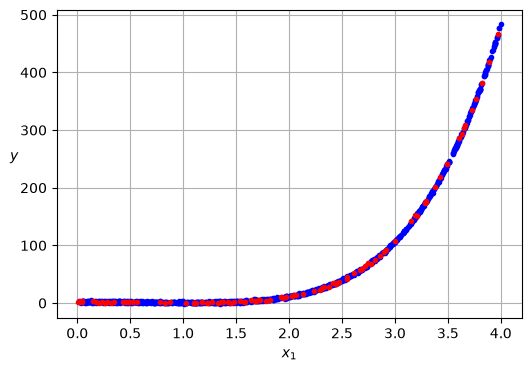

In [16]:
plt.figure(figsize=(6, 4))
plt.plot(X_train, y_train, "b.")
plt.plot(X_test, y_test, "r.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.grid()
plt.show()

Crea un modelo de regresión utilizando PolynomialFeatures, para ver cuál es el mejor degree representa gráficamente el error de entrenamiento y el error de prueba para diferentes degree.
Justifica que degree escoges y crea una pipeline para poder aplicar tu modelo.

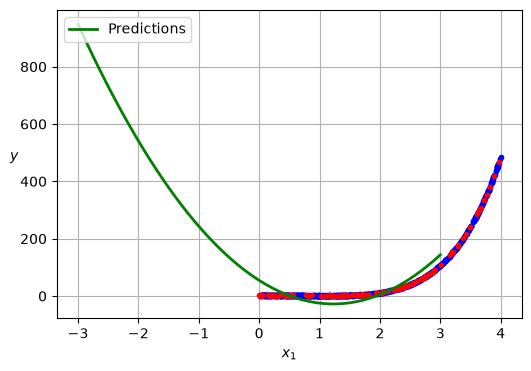

In [25]:
polinomial_modelo = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),StandardScaler(), LinearRegression())
polinomial_modelo.fit(X_train, y_train)

X_new = np.linspace(-3, 3, 100).reshape(100, 1)
y_new = polinomial_modelo.predict(X_new)

plt.figure(figsize=(6, 4))
plt.plot(X_train, y_train, "b.")
plt.plot(X_test, y_test, "r.")
plt.plot(X_new, y_new, "g-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()

Entrena el modelo y calcula el error en el conjunto de pruebas

Aplica al modelo algún tipo de regularización que mejore el modelo

Dibuja las curvas de aprendizaje para este último modelo e interpretalas

## EJERCICIO 6

Intenta predecir las emisiones de CO2 con el menor error posible (sigue todos los pasos incluido crear un script para que haga predicciones).

Prueba diferentes modelos para intentar construir el mejor modelo posible (explica todos los pasos que das hasta llegar a la solución, quiero ver también los modelos que pruebas y luego los rechazas)

Dataset: https://www.kaggle.com/datasets/midhundasl/co2-emission-of-cars-dataset